#Titanic Survival Analysis Exploratory Data Analysis
**Name:** Ayush Kumar

**Course / Batch:** Maincraft (01 September) (2026-2027)

**AICTE Student Id:** STU6a624b1fd56521784826655

#Problem Statement

The primary objective of this project is to perform a comprehensive Exploratory Data Analysis (EDA) on the Titanic passenger dataset (`tested.csv`) to uncover critical demographic and socio-economic patterns that influenced passenger survival. Real-world datasets often present data quality challenges, such as missing entries in key variables like `Age` and excessive missingness in non-essential columns like `Cabin`. To address these issues, missing `Age` values were imputed using the dataset mean, missing `Fare` values were filled with the median, and sparse columns were dropped to ensure data integrity. Furthermore, feature engineering techniques were applied to create meaningful categorical variables, including binned `AgeGroup` classifications and a combined `FamilySize` feature ($\text{SibSp} + \text{Parch} + 1$). By aggregating survival rates through `groupby` operations and displaying the findings via structured visualizations—such as age distribution histograms, correlation heatmaps, and annotated bar charts—this analysis provides clear insights into how age, group dynamics, and embarkation points impacted a passenger's likelihood of survival.

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# Set visualization parameters
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

In [35]:
print("=== STEP 1: DATA CLEANING & PREPROCESSING ===")
df = pd.read_csv("tested.csv")

# 1. Fill missing Age values with the column mean
age_mean = df["Age"].mean()
df["Age"].fillna(age_mean, inplace=True)

# 2. Fill missing Fare values with the median
fare_median = df["Fare"].median()
df["Fare"].fillna(fare_median, inplace=True)

# 3. Drop irrelevant or sparse columns
df.drop(columns=["Cabin"], inplace=True)

# Verify cleaning outcomes
print(f"Missing values remaining:\n{df.isnull().sum()}")

=== STEP 1: DATA CLEANING & PREPROCESSING ===
Missing values remaining:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [43]:
print("\n=== STEP 2: FEATURE ENGINEERING ===")

# Create Age Groups
bins = [0, 12, 18, 30, 50, 80]
labels = ["Child", "Teen", "YoungAdult", "Adult", "Senior"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)

# Create Family Size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Extract Title from Name
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
df["Title"] = df["Title"].replace(
    ["Col", "Rev", "Dr", "Dona", "Ms"], "Rare"
)

# Fare Quartile Groups
df["FareCategory"] = pd.qcut(
    df["Fare"], q=4, labels=["Low", "Medium", "High", "Very High"]
)

print("\n--- First 5 rows with new columns ---")
print(df[["Name", "AgeGroup", "FamilySize", "Title", "FareCategory"]].head())

print("\n--- Count of Passengers in Each Age Group ---")
print(df["AgeGroup"].value_counts())

print("\n--- Count of Passengers by Title ---")
print(df["Title"].value_counts())


=== STEP 2: FEATURE ENGINEERING ===

--- First 5 rows with new columns ---
                                           Name    AgeGroup  FamilySize Title  \
0                              Kelly, Mr. James       Adult           1    Mr   
1              Wilkes, Mrs. James (Ellen Needs)       Adult           2   Mrs   
2                     Myles, Mr. Thomas Francis      Senior           1    Mr   
3                              Wirz, Mr. Albert  YoungAdult           1    Mr   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  YoungAdult           3   Mrs   

  FareCategory  
0          Low  
1          Low  
2       Medium  
3       Medium  
4       Medium  

--- Count of Passengers in Each Age Group ---
AgeGroup
Adult         187
YoungAdult    146
Senior         31
Teen           29
Child          25
Name: count, dtype: int64

--- Count of Passengers by Title ---
Title
Mr        240
Miss       78
Mrs        72
Master     21
Rare        7
Name: count, dtype: int64


In [37]:
print("\n=== STEP 3: GROUPBY INSIGHTS ===")

print("\n1. Survival Rate by Age Group:")
print(
    df.groupby("AgeGroup", observed=False)["Survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Survival_Rate"})
)

print("\n2. Survival Rate by Embarkation Port:")
print(
    df.groupby("Embarked")["Survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Survival_Rate"})
)

print("\n3. Survival Rate by Family Size:")
print(
    df.groupby("FamilySize")["Survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Survival_Rate"})
)


=== STEP 3: GROUPBY INSIGHTS ===

1. Survival Rate by Age Group:
            count  Survival_Rate
AgeGroup                        
Child          25       0.480000
Teen           29       0.413793
YoungAdult    146       0.363014
Adult         187       0.320856
Senior         31       0.483871

2. Survival Rate by Embarkation Port:
          count  Survival_Rate
Embarked                      
C           102       0.392157
Q            46       0.521739
S           270       0.325926

3. Survival Rate by Family Size:
            count  Survival_Rate
FamilySize                      
1             253       0.268775
2              74       0.486486
3              57       0.526316
4              14       0.714286
5               7       0.285714
6               3       0.666667
7               4       0.250000
8               2       0.500000
11              4       0.500000



=== STEP 4: GENERATING SEABORN VISUALIZATIONS ===


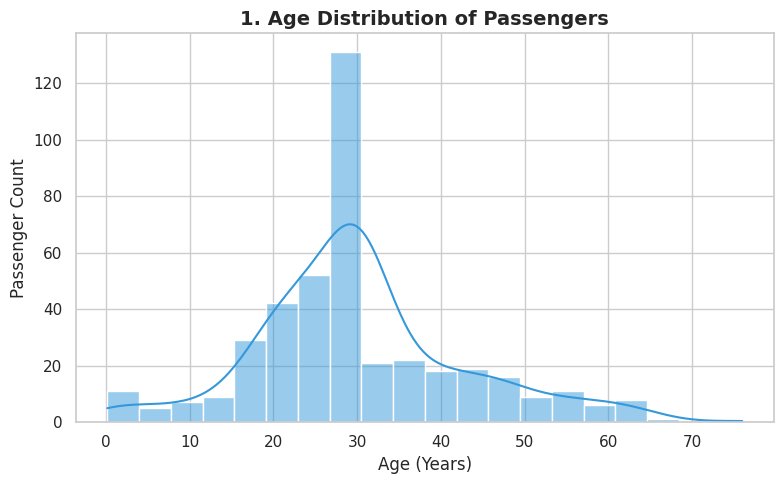

In [38]:
print("\n=== STEP 4: GENERATING SEABORN VISUALIZATIONS ===")
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], kde=True, bins=20, color="#3498db")
plt.title("1. Age Distribution of Passengers", fontsize=14, fontweight="bold")
plt.xlabel("Age (Years)")
plt.ylabel("Passenger Count")
plt.tight_layout()
plt.show()

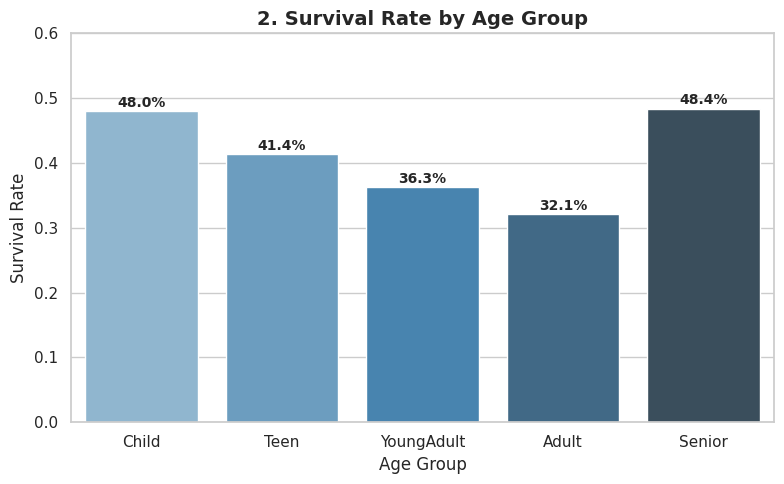

In [39]:
# Binning ages
bins = [0, 12, 18, 30, 50, 80]
labels = ["Child", "Teen", "YoungAdult", "Adult", "Senior"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)

plt.figure(figsize=(8, 5))
ax2 = sns.barplot(
    x="AgeGroup",
    y="Survived",
    data=df,
    palette="Blues_d",
    hue="AgeGroup",
    errorbar=None,
)
if ax2.get_legend() is not None:
    ax2.get_legend().remove()

plt.title("2. Survival Rate by Age Group", fontsize=14, fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.ylim(0, 0.6)

# Percentage Labels
for p in ax2.patches:
    ax2.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

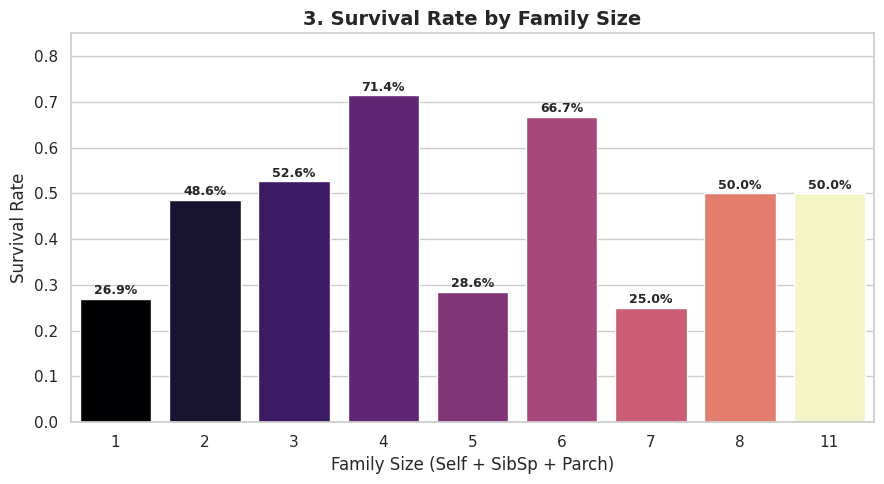

In [40]:
# Calculating family size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

plt.figure(figsize=(9, 5))
ax3 = sns.barplot(
    x="FamilySize",
    y="Survived",
    data=df,
    palette="magma",
    hue="FamilySize",
    errorbar=None,
)
if ax3.get_legend() is not None:
    ax3.get_legend().remove()

plt.title("3. Survival Rate by Family Size", fontsize=14, fontweight="bold")
plt.xlabel("Family Size (Self + SibSp + Parch)")
plt.ylabel("Survival Rate")
plt.ylim(0, 0.85)

# Percentage Labels
for p in ax3.patches:
    h = p.get_height()
    if not pd.isna(h) and h > 0:
        ax3.annotate(
            f"{h*100:.1f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="center",
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
        )

plt.tight_layout()
plt.show()

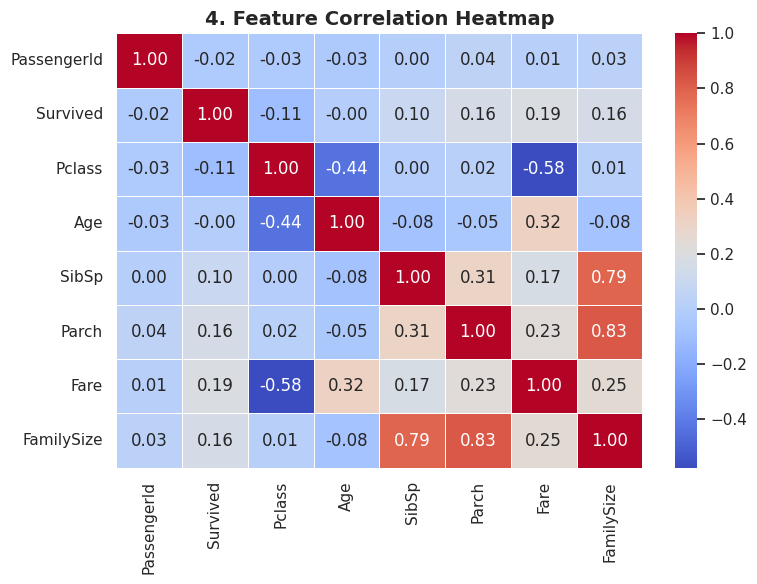

In [41]:
import numpy as np

df["Fare"].fillna(df["Fare"].median(), inplace=True)
numeric_cols = df.select_dtypes(include=[np.number])

plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("4. Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

#Conclusion
Through this Exploratory Data Analysis (EDA) on the Titanic dataset, several distinct patterns regarding passenger survival were uncovered:

#Gender & Class Impact:


*   Gender and passenger class were the single strongest predictors of survival. Female passengers across all classes and first-class passengers overall had significantly higher survival rates due to safety priorities during evacuation.

##Age & Demographics:

*   Children (0–12 years) had higher survival rates (48%) compared to young adults (36%), aligning with standard emergency protocols.
*   Seniors (50+ years) also showed an elevated survival rate (~48.4%), which is often tied to higher representation in upper-class accommodation tiers.

##Family Size & Group Dynamics:

*   Solo travelers faced lower survival chances (~26.9%).
*   Travelers in small family units (2 to 4 members) achieved the highest survival rates (reaching up to ~71.4%), likely benefiting from group assistance during evacuation. However, larger family sizes (5+) experienced reduced survival outcomes due to the difficulty of coordinating larger groups under panic.





##Port of Embarkation:

*   Passengers embarking from Queenstown (Q) (52.2%) and Cherbourg (C) (39.2%) saw higher survival rates than those from Southampton (S) (~32.6%), which directly correlates with the higher concentration of first-class tickets sold at those ports.
